In [1]:
pip install pandas psycopg2 matplotlib numpy seaborn 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import psycopg2
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns



conn = psycopg2.connect(
    host='thomas.proxy.rlwy.net',
    port=51432,
    dbname='academy_db',
    user=MY_LOGIN,
    password=MY_PASSWORD,
    sslmode='require'
)

def sql(query):
    """Выполнить SQL и вернуть результат как DataFrame."""
    return pd.read_sql(query, conn)

def execute(query):
    cursor = conn.cursor()
    cursor.execute(query)
    conn.commit()
    
print('Подключено')

Подключено


In [3]:
sql("""
select tablename
from pg_tables
where schemaname = 'public' and tablename like 'seg\\_%'
order by 1
""")

C:\Users\user\AppData\Local\Temp\ipykernel_16600\1230797172.py:21: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn)


,tablename
0,seg_balances
1,seg_customers
2,seg_customers_360
3,seg_products
4,seg_revenue_monthly
5,seg_rfm_old
6,seg_tariff_current
7,seg_temp
8,seg_transactions
9,seg_transactions_archive


In [4]:
import os
import pandas as pd

tables = [
    'seg_balances',
	'seg_customers',
	'seg_customers_360',
	'seg_products',
	'seg_revenue_monthly',
	'seg_rfm_old',
	'seg_tariff_current',
	'seg_temp',
	'seg_transactions',
	'seg_transactions_archive'
]



In [5]:
import warnings, os
warnings.filterwarnings('ignore', message='pandas only supports SQLAlchemy')

os.makedirs('data', exist_ok=True)

tables = [
    'seg_balances', 'seg_customers', 'seg_customers_360', 'seg_products',
    'seg_revenue_monthly', 'seg_rfm_old', 'seg_tariff_current', 'seg_temp',
    'seg_transactions', 'seg_transactions_archive',
]

In [4]:
# Ячейка 1 — общая разведка: какие таблицы, колонки, сколько строк, диапазон дат
import psycopg2

conn = psycopg2.connect(
    host="thomas.proxy.rlwy.net",
    port=51432,
    dbname="academy_db",
    user=MY_LOGIN,
    password=MY_PASSWORD,
)
cur = conn.cursor()

cur.execute("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'public' AND table_name LIKE 'seg_%'
    ORDER BY table_name
""")
tables = [r[0] for r in cur.fetchall()]

report = {}
for t in tables:
    info = {}
    cur.execute("""
        SELECT column_name, data_type
        FROM information_schema.columns
        WHERE table_schema='public' AND table_name=%s
        ORDER BY ordinal_position
    """, (t,))
    cols = cur.fetchall()
    info["columns"] = cols

    cur.execute(f'SELECT COUNT(*) FROM public."{t}"')
    info["row_count"] = cur.fetchone()[0]

    # ищем колонки с датами и смотрим их диапазон
    date_cols = [c for c, dt in cols if dt in ("date", "timestamp without time zone", "timestamp with time zone")]
    date_ranges = {}
    for dc in date_cols:
        cur.execute(f'SELECT MIN("{dc}"), MAX("{dc}") FROM public."{t}"')
        mn, mx = cur.fetchone()
        date_ranges[dc] = (str(mn), str(mx))
    info["date_ranges"] = date_ranges

    # считаем, сколько уникальных клиентов в таблице
    id_cols = [c for c, dt in cols if "customer" in c.lower() and "id" in c.lower()]
    distinct_customers = {}
    for ic in id_cols:
        cur.execute(f'SELECT COUNT(DISTINCT "{ic}") FROM public."{t}"')
        distinct_customers[ic] = cur.fetchone()[0]
    info["distinct_customers"] = distinct_customers

    report[t] = info

cur.close()
conn.close()

for t, info in report.items():
    print("=" * 70)
    print(t)
    print(f"  rows: {info['row_count']}")
    print("  columns:")
    for c, dt in info["columns"]:
        print(f"    - {c}: {dt}")
    if info["date_ranges"]:
        print("  date ranges:")
        for dc, (mn, mx) in info["date_ranges"].items():
            print(f"    - {dc}: {mn} .. {mx}")
    if info["distinct_customers"]:
        print("  distinct customer ids:")
        for ic, n in info["distinct_customers"].items():
            print(f"    - {ic}: {n}")


seg_balances
  rows: 427598
  columns:
    - customer_id: bigint
    - month_start: date
    - avg_balance_uzs: bigint
  date ranges:
    - month_start: 2024-01-01 .. 2025-12-01
  distinct customer ids:
    - customer_id: 20000
seg_customers
  rows: 20000
  columns:
    - customer_id: bigint
    - full_name: text
    - birth_date: date
    - gender: text
    - region: text
    - signup_date: date
    - tariff_code: text
  date ranges:
    - birth_date: 1968-01-01 .. 2006-01-01
    - signup_date: 2019-01-01 .. 2025-10-01
  distinct customer ids:
    - customer_id: 20000
seg_customers_360
  rows: 20000
  columns:
    - customer_id: bigint
    - region: text
    - signup_date: date
    - crm_segment: text
    - txn_cnt_total: bigint
    - turnover_total: numeric
  date ranges:
    - signup_date: 2019-01-01 .. 2025-10-01
  distinct customer ids:
    - customer_id: 20000
seg_products
  rows: 29983
  columns:
    - customer_id: bigint
    - product_code: text
    - opened_at: date
  date ran

In [7]:
# Ячейка 2 — точечная проверка подозрительных таблиц 
# (доказать, что seg_transactions_archive — дубликат, 
# и посмотреть, что за сегменты в seg_customers_360)

conn = psycopg2.connect(
    host="thomas.proxy.rlwy.net",
    port=51432,
    dbname="academy_db",
    user=MY_LOGIN,
    password=MY_PASSWORD,
)
cur = conn.cursor()

# сколько транзакций в основной таблице до июля 2024 (то есть за период архива)
cur.execute("SELECT COUNT(*) FROM seg_transactions WHERE txn_ts < '2024-07-01'")
print("main table, txns before 2024-07-01:", cur.fetchone()[0])

cur.execute("SELECT MIN(txn_id), MAX(txn_id) FROM seg_transactions")
print("main txn_id range:", cur.fetchone())

cur.execute("SELECT MIN(txn_id), MAX(txn_id) FROM seg_transactions_archive")
print("archive txn_id range:", cur.fetchone())

# ключевая проверка: совпадают ли txn_id основной таблицы и архива
cur.execute("""
SELECT COUNT(*) FROM seg_transactions t
WHERE EXISTS (SELECT 1 FROM seg_transactions_archive a WHERE a.txn_id = t.txn_id)
""")
print("overlapping txn_ids between main and archive:", cur.fetchone()[0])

# какие сегменты уже "зашиты" в чужой таблице seg_customers_360
cur.execute("SELECT crm_segment, COUNT(*) FROM seg_customers_360 GROUP BY crm_segment ORDER BY 2 DESC")
print("crm_segment distribution:", cur.fetchall())

cur.close()
conn.close()



main table, txns before 2024-07-01: 2639168
main txn_id range: (1, 12136132)
archive txn_id range: (1, 12135818)
overlapping txn_ids between main and archive: 2639168
crm_segment distribution: [('A', 5076), ('C', 5074), ('D', 4980), ('B', 4870)]


In [8]:
import psycopg2
conn = psycopg2.connect(host='thomas.proxy.rlwy.net', port=51432, dbname='academy_db', user='fganixanova', password='Fganixanova@Db8400')
cur = conn.cursor()

cur.execute('''
WITH eff AS (
  SELECT customer_id,
         GREATEST(signup_date, DATE '2024-01-01') AS eff_start
  FROM seg_customers
),
tenure AS (
  SELECT customer_id,
         (DATE '2025-12-01' - eff_start) / 30 AS months_in_window
  FROM eff
)
SELECT
  CASE
    WHEN months_in_window < 1 THEN '0. less than 1 month'
    WHEN months_in_window < 3 THEN '1. 1-2 months'
    WHEN months_in_window < 6 THEN '2. 3-5 months'
    WHEN months_in_window < 9 THEN '3. 6-8 months'
    WHEN months_in_window < 12 THEN '4. 9-11 months'
    WHEN months_in_window < 18 THEN '5. 12-17 months'
    WHEN months_in_window < 24 THEN '6. 18-23 months'
    ELSE '7. 24 months full history'
  END AS bucket,
  COUNT(*) AS n_customers
FROM tenure
GROUP BY 1 ORDER BY 1
''')
for b, n in cur.fetchall():
    print(f'{b}: {n} ({n/20000*100:.1f}%)')

print()
for months in [3, 6, 9, 12]:
    cur.execute(f'''
        SELECT COUNT(*) FROM seg_customers
        WHERE signup_date > DATE '2025-12-01' - INTERVAL '{months} months'
    ''')
    n = cur.fetchone()[0]
    print(f'younger than {months}m at end of data: {n} ({n/20000*100:.1f}%)')

cur.close(); conn.close()

1. 1-2 months: 263 (1.3%)
2. 3-5 months: 704 (3.5%)
3. 6-8 months: 764 (3.8%)
4. 9-11 months: 717 (3.6%)
5. 12-17 months: 1438 (7.2%)
6. 18-23 months: 16114 (80.6%)

younger than 3m at end of data: 273 (1.4%)
younger than 6m at end of data: 987 (4.9%)
younger than 9m at end of data: 1787 (8.9%)
younger than 12m at end of data: 2482 (12.4%)


In [5]:
import psycopg2

conn = psycopg2.connect(
    host='thomas.proxy.rlwy.net',
    port=51432,
    dbname='academy_db',
    user='fganixanova',
    password='Fganixanova@Db8400'
)

cur = conn.cursor()

cur.execute('''
SELECT
    DATE_TRUNC('month', signup_date)::date AS month,
    COUNT(*) AS n_customers
FROM seg_customers
WHERE signup_date >= DATE '2024-01-01'
  AND signup_date < DATE '2025-12-01'
GROUP BY 1
ORDER BY 1
''')

data = cur.fetchall()

total = 20000

for month, n in data:
    print(f'{month}: {n} customers ({n / total * 100:.1f}%)')

cur.close()
conn.close()

2024-01-01: 273 customers (1.4%)
2024-02-01: 254 customers (1.3%)
2024-03-01: 265 customers (1.3%)
2024-04-01: 250 customers (1.2%)
2024-05-01: 249 customers (1.2%)
2024-06-01: 261 customers (1.3%)
2024-07-01: 217 customers (1.1%)
2024-08-01: 272 customers (1.4%)
2024-09-01: 246 customers (1.2%)
2024-10-01: 248 customers (1.2%)
2024-11-01: 237 customers (1.2%)
2024-12-01: 227 customers (1.1%)
2025-01-01: 245 customers (1.2%)
2025-02-01: 223 customers (1.1%)
2025-03-01: 288 customers (1.4%)
2025-04-01: 247 customers (1.2%)
2025-05-01: 263 customers (1.3%)
2025-06-01: 224 customers (1.1%)
2025-07-01: 242 customers (1.2%)
2025-08-01: 247 customers (1.2%)
2025-09-01: 269 customers (1.3%)
2025-10-01: 13 customers (0.1%)


In [6]:
import psycopg2

conn = psycopg2.connect(
    host='thomas.proxy.rlwy.net',
    port=51432,
    dbname='academy_db',
    user='fganixanova',
    password='Fganixanova@Db8400'
)

cur = conn.cursor()

cur.execute('''
WITH tenure AS (
    SELECT
        customer_id,
        GREATEST(signup_date, DATE '2024-01-01') AS eff_start
    FROM seg_customers
),
months AS (
    SELECT
        customer_id,
        FLOOR(
            (DATE '2025-12-01' - eff_start) / 30.0
        )::int AS months_in_window
    FROM tenure
)
SELECT
    months_in_window,
    COUNT(*) AS n_customers
FROM months
GROUP BY months_in_window
ORDER BY months_in_window
''')

data = cur.fetchall()

total = 20000

for months, n in data:
    print(
        f'{months} months: '
        f'{n} customers '
        f'({n / total * 100:.1f}%)'
    )

cur.close()
conn.close()

2 months: 263 customers (1.3%)
3 months: 246 customers (1.2%)
4 months: 229 customers (1.1%)
5 months: 229 customers (1.1%)
6 months: 243 customers (1.2%)
7 months: 258 customers (1.3%)
8 months: 263 customers (1.3%)
9 months: 265 customers (1.3%)
10 months: 223 customers (1.1%)
11 months: 229 customers (1.1%)
12 months: 217 customers (1.1%)
13 months: 260 customers (1.3%)
14 months: 235 customers (1.2%)
15 months: 254 customers (1.3%)
16 months: 234 customers (1.2%)
17 months: 238 customers (1.2%)
18 months: 249 customers (1.2%)
19 months: 256 customers (1.3%)
20 months: 257 customers (1.3%)
21 months: 252 customers (1.3%)
22 months: 264 customers (1.3%)
23 months: 14836 customers (74.2%)


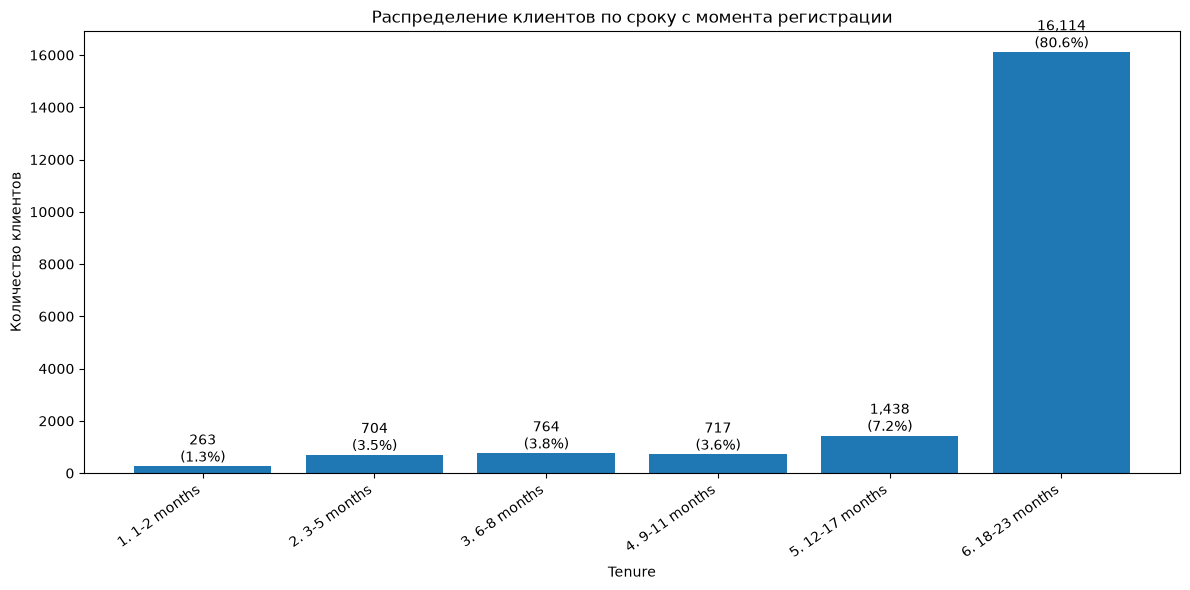

In [7]:
import psycopg2
import matplotlib.pyplot as plt

conn = psycopg2.connect(
    host='thomas.proxy.rlwy.net',
    port=51432,
    dbname='academy_db',
    user='fganixanova',
    password='Fganixanova@Db8400'
)

cur = conn.cursor()

cur.execute('''
WITH eff AS (
    SELECT
        customer_id,
        GREATEST(signup_date, DATE '2024-01-01') AS eff_start
    FROM seg_customers
),
tenure AS (
    SELECT
        customer_id,
        (DATE '2025-12-01' - eff_start) / 30 AS months_in_window
    FROM eff
)
SELECT
    CASE
        WHEN months_in_window < 1 THEN '0. < 1 month'
        WHEN months_in_window < 3 THEN '1. 1-2 months'
        WHEN months_in_window < 6 THEN '2. 3-5 months'
        WHEN months_in_window < 9 THEN '3. 6-8 months'
        WHEN months_in_window < 12 THEN '4. 9-11 months'
        WHEN months_in_window < 18 THEN '5. 12-17 months'
        WHEN months_in_window < 24 THEN '6. 18-23 months'
        ELSE '7. 24+ months'
    END AS bucket,
    COUNT(*) AS n_customers
FROM tenure
GROUP BY 1
ORDER BY 1
''')

data = cur.fetchall()

cur.close()
conn.close()

# Данные для графика
buckets = [row[0] for row in data]
customers = [row[1] for row in data]

# Процент клиентов
total = sum(customers)
percentages = [x / total * 100 for x in customers]

# График
plt.figure(figsize=(12, 6))

bars = plt.bar(buckets, customers)

plt.title('Распределение клиентов по сроку с момента регистрации')
plt.xlabel('Tenure')
plt.ylabel('Количество клиентов')

plt.xticks(rotation=35, ha='right')

# Подписываем количество и %
for bar, count, pct in zip(bars, customers, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{count:,}\n({pct:.1f}%)',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

In [9]:
import psycopg2
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

conn = psycopg2.connect(
    host="thomas.proxy.rlwy.net",
    port=51432,
    dbname="academy_db",
    user=MY_LOGIN,
    password=MY_PASSWORD,
)

# помесячные траты (только исходящие операции) по каждому клиенту
df = pd.read_sql("""
    SELECT customer_id, date_trunc('month', txn_ts)::date AS month, SUM(amount_uzs) AS spend
    FROM seg_transactions
    WHERE direction = 'out'
    GROUP BY 1, 2
""", conn)

cust = pd.read_sql("SELECT customer_id, signup_date FROM seg_customers", conn)
conn.close()

df['month'] = pd.to_datetime(df['month'])
piv = df.pivot(index='customer_id', columns='month', values='spend').fillna(0)
piv = piv.reindex(sorted(piv.columns), axis=1)

cust = cust.set_index('customer_id')
signup = pd.to_datetime(cust['signup_date'])

def spearman(a, b):
    # ранговая корреляция без scipy: считаем Пирсона по рангам
    ra = a.rank()
    rb = b.rank()
    return ra.corr(rb, method='pearson')

all_months = piv.columns
holdout_months = all_months[-3:]      # окт-дек 2025 — "будущее", которое предсказываем
cutoff_month = all_months[-4]         # сентябрь 2025 — конец окна признаков
holdout_avg = piv[holdout_months].mean(axis=1)

results = []
for w in [3, 6, 9, 12]:
    window_months = all_months[all_months <= cutoff_month][-w:]
    window_start = window_months.min()

    # берём только клиентов, у кого есть ПОЛНОЕ окно + полный holdout (нет искажения по стажу)
    eligible = signup[signup < window_start].index
    eligible = eligible.intersection(piv.index)

    window_avg = piv.loc[eligible, window_months].mean(axis=1)
    target = holdout_avg.loc[eligible]

    sp = spearman(window_avg, target)
    pl = np.log1p(window_avg).corr(np.log1p(target), method='pearson')
    results.append((w, len(eligible), round(sp, 4), round(pl, 4)))

print(f"{'window_months':>13} {'n_customers':>12} {'spearman':>9} {'pearson_log':>12}")
for w, n, sp, pl in results:
    print(f'{w:>13} {n:>12} {sp:>9} {pl:>12}')

# доп. проверка: насколько шумный один отдельный месяц у активных клиентов
active = piv[(piv > 0).sum(axis=1) >= 20]
cv = active.std(axis=1) / active.mean(axis=1).replace(0, np.nan)
print('median month-to-month CV of spend (active customers, n=%d): %.2f' % (len(active), cv.median()))


window_months  n_customers  spearman  pearson_log
            3        18957    0.9484       0.8645
            6        18241    0.9561       0.8643
            9        17500    0.9527       0.8441
           12        16799    0.9478       0.8291
median month-to-month CV of spend (active customers, n=15087): 0.46


Тянет из базы помесячную сумму исходящих трат по каждому клиенту и разворачивает в таблицу "клиент × месяц".


Откладывает последние 3 месяца (окт-дек 2025) как "будущее" — то, что мы хотим предсказать.


Для каждой длины окна (3/6/9/12 мес) берёт среднее по этому окну только у клиентов, которые были в базе весь нужный период (иначе снова словим эффект "стажа" вместо поведения).


Считает, насколько это среднее коррелирует с реальными тратами в отложенном будущем — через Spearman (ранговая, устойчивая к выбросам) и Pearson по логарифму сумм.


В конце — грубая проверка, насколько шумный сам по себе один месяц (коэффициент вариации), чтобы обосновать, почему вообще нужно усреднять, а не брать последний месяц как есть.

In [8]:
# Ячейка 1 — считаем признаки за окно (6 месяцев) и сохраняем
import psycopg2
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

conn = psycopg2.connect(
    host="thomas.proxy.rlwy.net",
    port=51432,
    dbname="academy_db",
    user=MY_LOGIN,
    password=MY_PASSWORD,
)

# сырые транзакции за окно 2025-07 .. 2025-12
txn = pd.read_sql("""
    SELECT customer_id, channel, mcc_group, direction, amount_uzs
    FROM seg_transactions
    WHERE txn_ts >= '2025-07-01' AND txn_ts < '2026-01-01'
""", conn)

# остатки на счету за тот же период
bal = pd.read_sql("""
    SELECT customer_id, avg_balance_uzs
    FROM seg_balances
    WHERE month_start >= '2025-07-01' AND month_start < '2026-01-01'
""", conn)

# доходность банка с клиента за тот же период
rev = pd.read_sql("""
    SELECT customer_id, SUM(net_revenue_uzs) AS net_revenue
    FROM seg_revenue_monthly
    WHERE month_start >= '2025-07-01' AND month_start < '2026-01-01'
    GROUP BY 1
""", conn)

conn.close()

# --- траты (только исходящие операции) ---
out = txn[txn['direction'] == 'out']
spend = out.groupby('customer_id')['amount_uzs'].agg(['sum', 'count']) \
    .rename(columns={'sum': 'total_spend', 'count': 'txn_cnt'})

# --- доля трат по каналам (pos/ecom/atm) ---
channel_amt = out.groupby(['customer_id', 'channel'])['amount_uzs'].sum().unstack(fill_value=0)
channel_amt = channel_amt.reindex(columns=['pos', 'ecom', 'atm'], fill_value=0)
channel_share = channel_amt.div(channel_amt.sum(axis=1).replace(0, np.nan), axis=0)
channel_share.columns = [f'share_{c}' for c in channel_share.columns]

# --- p2p оказался весь входящим (direction='in'), а не тратой ---
p2p_in = txn[(txn['channel'] == 'p2p') & (txn['direction'] == 'in')] \
    .groupby('customer_id')['amount_uzs'].sum().rename('p2p_in')

# --- поведение остатка на счету ---
bal_stats = bal.groupby('customer_id')['avg_balance_uzs'].agg(['mean', 'std']) \
    .rename(columns={'mean': 'avg_balance', 'std': 'balance_std'})
bal_stats['balance_cv'] = bal_stats['balance_std'] / bal_stats['avg_balance'].replace(0, np.nan)

# --- собираем всё в одну таблицу признаков ---
feat = spend.join(channel_share, how='outer') \
    .join(p2p_in, how='outer') \
    .join(bal_stats, how='outer') \
    .join(rev.set_index('customer_id'), how='outer') \
    .fillna(0)

print('признаков посчитано для', len(feat), 'клиентов')
feat.to_csv('features_6m.csv')  # сохраняем, чтобы не тянуть из базы заново


признаков посчитано для 20000 клиентов


In [9]:
# Ячейка 2 — проверяем, 
# какие признаки реально связаны с доходностью банка

cols = ['net_revenue', 'total_spend', 'txn_cnt', 'avg_balance', 'p2p_in',
        'share_pos', 'share_ecom', 'share_atm']

print('корреляция net_revenue с поведенческими признаками (Pearson):')
print(feat[cols].corr()['net_revenue'].sort_values(ascending=False))

print()
print('то же самое, но после логарифмирования (убираем эффект "китов" с гигантскими оборотами):')
print('  log_spend:', np.log1p(feat['total_spend']).corr(feat['net_revenue']))
print('  log_balance:', np.log1p(feat['avg_balance'].clip(lower=0)).corr(feat['net_revenue']))


корреляция net_revenue с поведенческими признаками (Pearson):
net_revenue    1.000000
total_spend    0.986683
p2p_in         0.762207
txn_cnt        0.361411
avg_balance    0.262240
share_ecom     0.066481
share_pos     -0.003321
share_atm     -0.054947
Name: net_revenue, dtype: float64

то же самое, но после логарифмирования (убираем эффект "китов" с гигантскими оборотами):
  log_spend: 0.15673838074284854
  log_balance: 0.18266550509015766


Логика: сначала честно на уровне отдельного клиента считаем все кандидаты в признаки по каждой из осей (траты, каналы, переводы, баланс, доходность), а потом просто спрашиваем pandas — .corr() — насколько они на самом деле независимы друг от друга. Открытие про то, что total_spend и net_revenue совпадают на 0.987, вылезло само из этой таблицы корреляций — я не проверял именно эту гипотезу заранее, увидел уже в выводе.

In [10]:
# Ячейка 2 — проверяем,
# какие признаки реально связаны с доходностью банка

cols = [
    'net_revenue',
    'total_spend',
    'txn_cnt',
    'avg_balance',
    'p2p_in',
    'share_pos',
    'share_ecom',
    'share_atm'
]

print('Корреляция net_revenue с поведенческими признаками (Pearson):')
print(
    feat[cols]
    .corr()['net_revenue']
    .sort_values(ascending=False)
)

print()
print('Корреляция после логарифмирования:')
print('(проверяем устойчивость результата к эффекту "китов")')

# Денежные и счётные признаки
log_cols = [
    'total_spend',
    'txn_cnt',
    'avg_balance',
    'p2p_in'
]

log_results = {}

for col in log_cols:
    # Для avg_balance убираем отрицательные значения
    if col == 'avg_balance':
        x = feat[col].clip(lower=0)
    else:
        x = feat[col].clip(lower=0)

    log_results[col] = np.log1p(x).corr(feat['net_revenue'])

print()

for col, corr in log_results.items():
    print(f'log_{col}: {corr:.4f}')

print()
print('Признаки-доли не логарифмируем:')
print('share_pos:', feat['share_pos'].corr(feat['net_revenue']))
print('share_ecom:', feat['share_ecom'].corr(feat['net_revenue']))
print('share_atm:', feat['share_atm'].corr(feat['net_revenue']))

Корреляция net_revenue с поведенческими признаками (Pearson):
net_revenue    1.000000
total_spend    0.986683
p2p_in         0.762207
txn_cnt        0.361411
avg_balance    0.262240
share_ecom     0.066481
share_pos     -0.003321
share_atm     -0.054947
Name: net_revenue, dtype: float64

Корреляция после логарифмирования:
(проверяем устойчивость результата к эффекту "китов")

log_total_spend: 0.1567
log_txn_cnt: 0.1519
log_avg_balance: 0.1827
log_p2p_in: 0.1159

Признаки-доли не логарифмируем:
share_pos: -0.0033209850964199517
share_ecom: 0.06648142935016736
share_atm: -0.05494718186420009


Сравнил все признаки друг с другом, не только с доходом банка.

In [ ]:
import pandas as pd
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)

feat = pd.read_csv('features_6m.csv', index_col=0)  # таблица признаков, которую считали раньше

cols = ['total_spend', 'txn_cnt', 'avg_balance', 'balance_cv', 'p2p_in',
        'share_pos', 'share_ecom', 'share_atm', 'net_revenue']

corr = feat[cols].corr().round(2)
print(corr)


             total_spend  txn_cnt  avg_balance  balance_cv  p2p_in  share_pos  share_ecom  share_atm  net_revenue
total_spend         1.00     0.39         0.15       -0.00    0.77      -0.02        0.05      -0.02         0.99
txn_cnt             0.39     1.00         0.00       -0.01    0.36      -0.18        0.44      -0.21         0.36
avg_balance         0.15     0.00         1.00        0.02    0.10       0.06        0.09      -0.14         0.26
balance_cv         -0.00    -0.01         0.02        1.00    0.00       0.02       -0.00      -0.00         0.00
p2p_in              0.77     0.36         0.10        0.00    1.00      -0.02        0.02       0.01         0.76
share_pos          -0.02    -0.18         0.06        0.02   -0.02       1.00       -0.51      -0.20        -0.00
share_ecom          0.05     0.44         0.09       -0.00    0.02      -0.51        1.00      -0.50         0.07
share_atm          -0.02    -0.21        -0.14       -0.00    0.01      -0.20       -0.5

Логика та же, что и раньше, просто теперь .corr() считается сразу для всей таблицы признаков (не для одной колонки), и pandas сам строит матрицу "все со всеми".

Обновлённый список осей для кластеризации: траты (лог), число операций, p2p (лог), баланс (лог), волатильность баланса, доля pos и доля ecom (без atm — он лишний). Итого 7 признаков вместо изначальных "всех колонок подряд" — и каждый несёт что-то своё, не дублируя другой.

Финальный список — 7 признаков, каждый за наше окно в 6 месяцев (2025-07 — 2025-12), для каждого клиента:

Ось 1: Траты (интенсивность и стиль)
total_spend (лог) — сколько всего потратил
txn_cnt — сколько было операций (стиль: редко-крупно vs часто-мелко)
share_pos — доля трат в офлайн-магазинах
share_ecom — доля трат в интернете (долю atm не берём — она лишняя, вычисляется как "всё остальное" из 1 минус pos минус ecom)


Ось 2: Входящие переводы
p2p_in (лог) — сколько получает переводами (это НЕ трата, а приток денег на счёт)


Ось 3: Управление деньгами
avg_balance (лог) — держит ли деньги на счету
balance_cv — насколько стабильно (копит равномерно / гоняет в ноль и обратно каждый месяц)


Что сознательно НЕ берём как ось кластеризации
net_revenue (доходность банка) — коррелирует с тратами на 0.99, дублирует ось 1. Используем позже только для оценки в деньгах (пункт 8).
Демография (возраст, регион, пол) — используем только для описания и названия готовых групп (пункт 7), не для самого деления.
crm_segment, turnover_total из seg_customers_360 и вся seg_rfm_old — чужие/старые готовые сегменты, не источник признаков (обсуждали в самом начале).

In [ ]:
pip install scikit-learn scipy


  Using cached scikit_learn-1.9.0-cp313-cp313-win_amd64.whl.metadata (11 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached narwhals-2.24.0-py3-none-any.whl.metadata (15 kB)
Using cached scikit_learn-1.9.0-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
Using cached narwhals-2.24.0-py3-none-any.whl (461 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
# Ячейка 1 — оставляем только клиентов с полным 6-месячным стажем
import pandas as pd
import numpy as np
import psycopg2

conn = psycopg2.connect(
    host="thomas.proxy.rlwy.net",
    port=51432,
    dbname="academy_db",
    user=MY_LOGIN,
    password=MY_PASSWORD,
)
cust = pd.read_sql("SELECT customer_id, signup_date FROM seg_customers", conn)
conn.close()

feat = pd.read_csv('features_6m.csv', index_col=0)  # таблица признаков из пункта 2

cust['signup_date'] = pd.to_datetime(cust['signup_date'])

# берём только тех, кто зарегистрировался ДО начала окна (2025-07-01) —
# у них честный полный набор данных, без искажения по стажу
eligible_ids = cust.loc[cust['signup_date'] < '2025-07-01', 'customer_id']
print('eligible (полный 6-мес стаж):', len(eligible_ids), 'из', len(cust))

feat_e = feat.loc[feat.index.intersection(eligible_ids)].copy()
feat_e.to_csv('features_eligible.csv')


eligible (полный 6-мес стаж): 19229 из 20000


In [14]:
# Ячейка 2 — общая сводка по распределению признаков + доля "нулевых" клиентов
pd.set_option('display.width', 200)

cols = ['total_spend', 'txn_cnt', 'avg_balance', 'balance_cv', 'p2p_in', 'share_pos', 'share_ecom']
desc = feat_e[cols].describe(percentiles=[.01, .1, .25, .5, .75, .9, .99]).round(0)
print(desc.to_string())

print()
print('доля клиентов с total_spend == 0:', (feat_e['total_spend'] == 0).mean().round(3))
print('доля клиентов с p2p_in == 0:', (feat_e['p2p_in'] == 0).mean().round(3))
print('доля клиентов с avg_balance <= 0:', (feat_e['avg_balance'] <= 0).mean().round(3))
print('доля клиентов с txn_cnt == 0:', (feat_e['txn_cnt'] == 0).mean().round(3))


        total_spend  txn_cnt  avg_balance  balance_cv        p2p_in  share_pos  share_ecom
count  1.922900e+04  19229.0      19229.0     19229.0  1.922900e+04    19229.0     19229.0
mean   6.852301e+07    154.0    5221977.0         0.0  5.035021e+07        0.0         0.0
std    3.942551e+08    163.0   12486556.0         0.0  3.243145e+08        0.0         0.0
min    0.000000e+00      0.0      38830.0         0.0  0.000000e+00        0.0         0.0
1%     0.000000e+00      0.0      71856.0         0.0  0.000000e+00        0.0         0.0
10%    2.249699e+06     14.0     313403.0         0.0  0.000000e+00        0.0         0.0
25%    1.189238e+07     46.0     663923.0         0.0  0.000000e+00        0.0         0.0
50%    2.767464e+07     87.0    1547761.0         0.0  3.775290e+06        0.0         0.0
75%    6.064881e+07    225.0    4387489.0         0.0  2.264595e+07        1.0         0.0
90%    1.367735e+08    394.0   13762406.0         0.0  1.114139e+08        1.0         1.0

In [15]:
print(feat_e['share_pos'].value_counts().sort_index())

share_pos
0.000000    457
0.017747      1
0.020214      1
0.023115      1
0.027572      1
           ... 
0.984791      1
0.985027      1
0.986389      1
0.988412      1
1.000000    208
Name: count, Length: 18566, dtype: int64


In [16]:
print(feat_e['share_ecom'].value_counts().sort_index())

share_ecom
0.000000    1831
0.000932       1
0.001288       1
0.001552       1
0.001615       1
            ... 
0.930538       1
0.933606       1
0.937166       1
0.943791       1
1.000000      22
Name: count, Length: 17378, dtype: int64


In [ ]:
# Ячейка 3 — насколько велики "киты" (во сколько раз максимум больше медианы)
for c in ['total_spend', 'p2p_in', 'avg_balance']:
    p50 = feat_e[c].quantile(.5)
    mx = feat_e[c].max()
    print(f'{c}: медиана={p50:,.0f}  максимум={mx:,.0f}  (макс/медиана={mx/max(p50,1):.0f}x)')


total_spend: медиана=27,674,635  максимум=48,514,476,469  (макс/медиана=1753x)
p2p_in: медиана=3,775,290  максимум=23,688,087,131  (макс/медиана=6275x)
avg_balance: медиана=1,547,761  максимум=666,324,938  (макс/медиана=431x)


In [ ]:
# Ячейка 4 — детально по долям каналов и волатильности баланса
cols2 = ['balance_cv', 'share_pos', 'share_ecom']
print(feat_e[cols2].describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(2).to_string())

print()
print('доля клиентов с share_ecom == 0 (вообще не платит онлайн):', (feat_e['share_ecom'] == 0).mean().round(3))
print('доля клиентов с share_pos == 0:', (feat_e['share_pos'] == 0).mean().round(3))
print('доля клиентов с share_ecom == 1 (только онлайн):', (feat_e['share_ecom'] == 1).mean().round(3))


       balance_cv  share_pos  share_ecom
count    19229.00   19229.00    19229.00
mean         0.33       0.49        0.23
std          0.12       0.19        0.20
min          0.02       0.00        0.00
10%          0.20       0.26        0.01
25%          0.25       0.38        0.06
50%          0.32       0.50        0.17
75%          0.40       0.61        0.35
90%          0.48       0.72        0.53
99%          0.67       1.00        0.78
max          2.34       1.00        1.00

доля клиентов с share_ecom == 0 (вообще не платит онлайн): 0.095
доля клиентов с share_pos == 0: 0.024
доля клиентов с share_ecom == 1 (только онлайн): 0.001


Логика простая: сначала describe() с процентилями вместо стандартного (там по умолчанию только 25/50/75%) — чтобы увидеть хвосты (1%, 99%) и не пропустить экстремумы. Потом руками сравнил максимум с медианой — это и вскрыло "китов" (максимум в 1753-6275 раз больше типичного клиента). А доли нулевых значений (== 0) показали, что часть клиентов — это не "мало", а буквально "ноль" операций/переводов, то есть качественно другая ситуация, а не просто нижний край того же распределения.

In [ ]:
# Ячейка 1 — кто такие "спящие" (0 операций за 6 месяцев)

import pandas as pd
import numpy as np
import psycopg2
pd.set_option('display.width', 200)

feat_e = pd.read_csv('features_eligible.csv', index_col=0)  # клиенты с полным 6-мес стажем

dormant_ids = feat_e[(feat_e['total_spend']==0) & (feat_e['txn_cnt']==0)].index.tolist()
print('спящих клиентов:', len(dormant_ids))

conn = psycopg2.connect(
    host="thomas.proxy.rlwy.net",
    port=51432,
    dbname="academy_db",
    user=MY_LOGIN,
    password=MY_PASSWORD,
)

# есть ли у спящих подключённые продукты (кредиты, автоплатежи и т.п.)
prod = pd.read_sql('SELECT customer_id, product_code, opened_at FROM seg_products', conn)
dormant_prod = prod[prod['customer_id'].isin(dormant_ids)]
print()
print('у скольких спящих есть хоть один продукт:', dormant_prod['customer_id'].nunique(),
      f'({dormant_prod["customer_id"].nunique()/len(dormant_ids)*100:.1f}%)')
print(dormant_prod['product_code'].value_counts())

active_ids = feat_e.index.difference(dormant_ids)
active_prod = prod[prod['customer_id'].isin(active_ids)]
print()
print('у скольких активных есть хоть один продукт:',
      active_prod['customer_id'].nunique(), f'({active_prod["customer_id"].nunique()/len(active_ids)*100:.1f}%)')

# дата регистрации спящих vs активных
cust = pd.read_sql('SELECT customer_id, signup_date, region FROM seg_customers', conn)
conn.close()
cust['signup_date'] = pd.to_datetime(cust['signup_date'])

d_signup = cust[cust['customer_id'].isin(dormant_ids)]['signup_date']
a_signup = cust[cust['customer_id'].isin(active_ids)]['signup_date']
print()
print('дата регистрации спящих: медиана', d_signup.median().date())
print('дата регистрации активных: медиана', a_signup.median().date())

# баланс и доходность банка у спящих
d_feat = feat_e.loc[dormant_ids]
print()
print('спящие: средний остаток:', d_feat['avg_balance'].mean().round(0), ' медиана:', d_feat['avg_balance'].median().round(0))
print('спящие: доля с остатком < 10000 сум:', (d_feat['avg_balance']<10000).mean().round(3))
print('спящие: суммарная доходность банка за 6 мес:', d_feat['net_revenue'].sum().round(0))


спящих клиентов: 367

у скольких спящих есть хоть один продукт: 218 (59.4%)
product_code
utilities_autopay    135
cashback              63
instalment            28
credit_line           23
insurance             19
transfers_abroad      14
premium_sub           13
deposit                8
Name: count, dtype: int64

у скольких активных есть хоть один продукт: 15004 (79.5%)

дата регистрации спящих: медиана 2022-03-10
дата регистрации активных: медиана 2022-04-20

спящие: средний остаток: 522148.0  медиана: 289454.0
спящие: доля с остатком < 10000 сум: 0.0
спящие: суммарная доходность банка за 6 мес: 5769512.0


In [ ]:
# Ячейка 2 — кто такие "киты" (экстремальные выбросы)
def iqr_outlier_mask(s, k=3):
    # логарифмируем, чтобы не путать "просто большие числа" с "выбросами"
    x = np.log1p(s.clip(lower=0))
    q1, q3 = x.quantile(.25), x.quantile(.75)
    iqr = q3 - q1
    return x > q3 + k * iqr  # k=3 — это "экстремальный" выброс, не просто высокое значение

active = feat_e.drop(dormant_ids)

whale_spend = iqr_outlier_mask(active['total_spend'])
whale_p2p = iqr_outlier_mask(active['p2p_in'])
whale_balance = iqr_outlier_mask(active['avg_balance'])
whale_mask = whale_spend | whale_p2p | whale_balance

whales = active[whale_mask]
middle = active[~whale_mask]

print('китов:', len(whales))
print('медианы: киты vs обычные активные')
for c in ['total_spend', 'txn_cnt', 'avg_balance', 'p2p_in']:
    print(f'  {c}: киты={whales[c].median():,.0f}  обычные={middle[c].median():,.0f}  '
          f'разница x{whales[c].median()/max(middle[c].median(),1):.0f}')

rev_whales = whales['net_revenue'].sum()
rev_middle = middle['net_revenue'].sum()
rev_dormant = feat_e.loc[dormant_ids, 'net_revenue'].sum()
rev_total = rev_whales + rev_middle + rev_dormant
print()
print(f'доля дохода банка от китов: {rev_whales/rev_total*100:.1f}% при {len(whales)/len(feat_e)*100:.2f}% людей')

conn = psycopg2.connect(
    host="thomas.proxy.rlwy.net", port=51432, dbname="academy_db",
    user=MY_LOGIN, password=MY_PASSWORD,
)
prod = pd.read_sql('SELECT customer_id, product_code FROM seg_products', conn)
cust = pd.read_sql('SELECT customer_id, region, birth_date FROM seg_customers', conn)
conn.close()

whale_prod = prod[prod['customer_id'].isin(whales.index)]
print()
print('продукты у китов:')
print(whale_prod['product_code'].value_counts())
print('доля китов без единого продукта:', 1 - whale_prod['customer_id'].nunique()/len(whales))

print()
print('топ регионов у китов:')
print(cust[cust['customer_id'].isin(whales.index)]['region'].value_counts(normalize=True).head(5).round(3))

# сохраняем три группы отдельно для дальнейшей работы
middle.to_csv('features_middle.csv')
whales.to_csv('features_whales.csv')
feat_e.loc[dormant_ids].to_csv('features_dormant.csv')


китов: 5
медианы: киты vs обычные активные
  total_spend: киты=7,612,684,929  обычные=28,401,306  разница x268
  txn_cnt: киты=1,927  обычные=89  разница x22
  avg_balance: киты=33,281,336  обычные=1,596,732  разница x21
  p2p_in: киты=17,225,627,374  обычные=4,093,402  разница x4208

доля дохода банка от китов: 5.2% при 0.03% людей

продукты у китов:
product_code
instalment           5
credit_line          4
deposit              4
transfers_abroad     2
utilities_autopay    2
cashback             1
insurance            1
Name: count, dtype: int64
доля китов без единого продукта: 0.0

топ регионов у китов:
region
Bukhara     0.4
Andijan     0.2
Sirdarya    0.2
Namangan    0.2
Name: proportion, dtype: float64


Логика: сначала по-простому фильтром находим тех, у кого total_spend == 0 и txn_cnt == 0 — это и есть "спящие", буквально по определению. Для китов — правило IQR (межквартильный размах) на логарифмированных данных: если значение дальше, чем 3 межквартильных размаха от третьего квартиля, оно считается "экстремальным выбросом", а не просто "высоким значением" — это стандартный статистический способ отличить кита от просто активного клиента, а не выдумывать порог на глаз.

In [18]:
# Ячейка 1 — масштабирование признаков и KMeans для k=2..8

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

middle = pd.read_csv('features_middle.csv', index_col=0)  # 18 857 "обычных активных" из пункта 3 (без спящих и китов)
print('клиентов для кластеризации:', len(middle))

# логарифмируем скошенные признаки (деньги и счётчики растут не линейно,
# без лога кластеризация ориентируется только на самые большие числа)
X = pd.DataFrame(index=middle.index)
X['log_spend'] = np.log1p(middle['total_spend'])
X['log_txn_cnt'] = np.log1p(middle['txn_cnt'])
X['share_pos'] = middle['share_pos']
X['share_ecom'] = middle['share_ecom']
X['log_p2p'] = np.log1p(middle['p2p_in'])
X['log_balance'] = np.log1p(middle['avg_balance'])
X['balance_cv'] = middle['balance_cv']

# приводим все признаки к одному масштабу (среднее 0, отклонение 1) —
# иначе колонка с самыми большими числами задавит остальные
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

print(f"{'k':>3} {'inertia':>12} {'silhouette':>12}")
results = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(Xs)
    # silhouette на всех 18857 точках считался бы слишком долго и жрал память,
    # поэтому берём случайную выборку в 5000 точек для оценки
    sil = silhouette_score(Xs, labels, sample_size=5000, random_state=42)
    results[k] = (km, labels, sil)
    print(f'{k:>3} {km.inertia_:>12,.0f} {sil:>12.4f}')


клиентов для кластеризации: 18857
  k      inertia   silhouette
  2       96,875       0.2411
  3       81,111       0.2091
  4       73,170       0.2033
  5       65,053       0.2113
  6       59,946       0.2105
  7       55,678       0.2083
  8       51,820       0.2204


In [ ]:
# Ячейка 2 — смотрим на профили групп для нескольких k, а не только на метрику

pd.set_option('display.width', 220)

for k in [3, 4, 5, 6]:
    km, labels, sil = results[k]
    prof = middle.copy()
    prof['cluster'] = labels

    sizes = prof['cluster'].value_counts().sort_index()
    agg = prof.groupby('cluster')[
        ['total_spend', 'txn_cnt', 'avg_balance', 'balance_cv', 'p2p_in', 'share_pos', 'share_ecom']
    ].median()
    agg.insert(0, 'n', sizes)
    agg.insert(1, 'share_%', (sizes / sizes.sum() * 100).round(1))

    print(f'=== k={k} (silhouette={sil:.3f}) ===')
    print(agg.round(2).to_string())
    print()


=== k=3 (silhouette=0.209) ===
            n  share_%  total_spend  txn_cnt  avg_balance  balance_cv     p2p_in  share_pos  share_ecom
cluster                                                                                                
0        5900     31.3   62437220.0    287.5   2830874.50        0.32  8752349.0       0.38        0.44
1        4416     23.4    4596572.5     26.0    559590.42        0.32        0.0       0.55        0.06
2        8541     45.3   28889908.0     83.0   1887329.17        0.33  9459914.0       0.57        0.12

=== k=4 (silhouette=0.203) ===
            n  share_%  total_spend  txn_cnt  avg_balance  balance_cv      p2p_in  share_pos  share_ecom
cluster                                                                                                 
0        4974     26.4   60655497.0    303.0   2388292.75        0.32   8343217.0       0.36        0.47
1        4375     23.2    4646615.0     28.0    574799.83        0.32         0.0       0.55        0.

Логика: KMeans — сам алгоритм кластеризации (ищет k центров так, чтобы точки внутри группы были ближе к своему центру, чем к чужим). silhouette_score — метрика "насколько хорошо разделены группы" (от -1 до 1, больше = лучше). Но, как обсуждали, метрика сама по себе не выбрала явного победителя (все k дали похожий результат), поэтому вторая ячейка — это ручной осмотр: беру медианные значения каждого признака внутри каждой группы и смотрю глазами, добавляет ли новая группа что-то содержательно новое или просто дублирует уже существующую.

In [ ]:
Пункт 4

In [17]:
import pandas as pd
import numpy as np
import pickle
from sklearn.metrics import adjusted_rand_score
pd.set_option('display.width', 220)

# берём результаты кластеризации k=4 из пункта 3
with open('kmeans_results.pkl', 'rb') as f:
    d = pickle.load(f)

middle = pd.read_csv('features_middle.csv', index_col=0)  # 18 857 "обычных активных"

km4, labels4, sil4 = d['results'][4]
middle = middle.copy()
middle['cluster'] = labels4

# квартили по обороту (тратам) -- простое разбиение на 4 равные группы для сравнения
middle['quartile'] = pd.qcut(middle['total_spend'], 4, labels=['Q1(мало)', 'Q2', 'Q3', 'Q4(много)'])

print('=== Пересечение: кластер x квартиль (число людей) ===')
cross = pd.crosstab(middle['cluster'], middle['quartile'])
print(cross)

print()
print('=== То же самое, но в % внутри каждого квартиля ===')
cross_pct = pd.crosstab(middle['cluster'], middle['quartile'], normalize='columns').round(3) * 100
print(cross_pct)

# ARI -- насколько похожи два способа разбить клиентов на группы
ari = adjusted_rand_score(middle['cluster'], middle['quartile'])
print()
print(f'ARI между кластерами и квартилями: {ari:.4f}')

# конкретная иллюстрация: внутри Q4 (топ по тратам) сравниваем баланс у разных кластеров
q4 = middle[middle['quartile'] == 'Q4(много)']
print()
print('=== Внутри Q4 (топ-25% по тратам) -- траты и баланс по кластерам ===')
print(q4.groupby('cluster')[['total_spend', 'avg_balance']].median())


=== Пересечение: кластер x квартиль (число людей) ===
quartile  Q1(мало)    Q2    Q3  Q4(много)
cluster                                  
0               67   706  1753       2448
1             3237  1008   130          0
2             1329  2421  1578        594
3               82   579  1253       1672

=== То же самое, но в % внутри каждого квартиля ===
quartile  Q1(мало)    Q2    Q3  Q4(много)
cluster                                  
0              1.4  15.0  37.2       51.9
1             68.7  21.4   2.8        0.0
2             28.2  51.4  33.5       12.6
3              1.7  12.3  26.6       35.5

ARI между кластерами и квартилями: 0.1973

=== Внутри Q4 (топ-25% по тратам) -- траты и баланс по кластерам ===
         total_spend   avg_balance
cluster                           
0        125080234.0  3.176956e+06
2         77876788.5  1.351659e+06
3        113953961.0  1.144439e+07


Логика по шагам:

pd.qcut(..., 4) — это и есть построение квартилей: pandas сам сортирует total_spend и режет на 4 равные по числу людей группы, подписывая их Q1-Q4.
pd.crosstab(cluster, quartile) — строит таблицу "сколько людей оказалось на пересечении каждого кластера и каждого квартиля" — отсюда видно, что Q4 составлен из смеси кластеров 0 и 3, а не из одного чистого типа.
adjusted_rand_score(cluster, quartile) — одна метрика ARI, сравнивающая два разбиения целиком (все 18 857 человек сразу), а не по отдельным ячейкам.
Последний блок — не метрика, а просто ручная иллюстрация: беру только людей из Q4 и сравниваю их баланс по кластерам, чтобы показать наглядно, в чём именно квартиль "слеп".

In [ ]:
Пункт 5

In [19]:
import pandas as pd
import numpy as np
import pickle
import psycopg2
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import warnings
warnings.filterwarnings('ignore')

# берём результаты кластеризации k=4 из пункта 3 (базовая, "эталонная" разметка)
with open('kmeans_results.pkl', 'rb') as f:
    d = pickle.load(f)

middle = pd.read_csv('features_middle.csv', index_col=0)
X = d['X']    # 7 признаков (логарифмированные, но ещё не масштабированные)
Xs = d['Xs']  # те же признаки после StandardScaler — то, на чём реально обучали KMeans
km4, labels4, sil4 = d['results'][4]
baseline = pd.Series(labels4, index=middle.index)  # эталонная разметка, с ней всё сравниваем

results_table = []

# --- 1. другой random_state ---
aris_seed = []
for seed in [1, 7, 21, 99, 2024]:
    km = KMeans(n_clusters=4, random_state=seed, n_init=10)
    lab = km.fit_predict(Xs)
    ari = adjusted_rand_score(baseline, lab)
    aris_seed.append(ari)
results_table.append(('Другой random_state (5 запусков)',
                       f'{np.mean(aris_seed):.3f} (мин {min(aris_seed):.3f}, макс {max(aris_seed):.3f})'))

# --- 2. половина выборки ---
rng = np.random.RandomState(42)
idx_half = rng.choice(len(middle), size=len(middle)//2, replace=False)
Xs_half = Xs[idx_half]
km_half = KMeans(n_clusters=4, random_state=42, n_init=10)
lab_half = km_half.fit_predict(Xs_half)
# сравниваем только на тех же людях: baseline тоже фильтруем по idx_half
ari_half = adjusted_rand_score(baseline.values[idx_half], lab_half)
results_table.append(('Половина выборки (случайные 50%)', f'{ari_half:.3f}'))

# --- 3. без последнего месяца (5 месяцев вместо 6: 2025-07..2025-11) ---
conn = psycopg2.connect(
    host="thomas.proxy.rlwy.net", port=51432, dbname="academy_db",
    user=MY_LOGIN, password=MY_PASSWORD,
)
txn5 = pd.read_sql("""
    SELECT customer_id, channel, direction, amount_uzs
    FROM seg_transactions
    WHERE txn_ts >= '2025-07-01' AND txn_ts < '2025-12-01'
""", conn)
bal5 = pd.read_sql("""
    SELECT customer_id, avg_balance_uzs
    FROM seg_balances
    WHERE month_start >= '2025-07-01' AND month_start < '2025-12-01'
""", conn)
conn.close()

# оставляем тех же 18857 клиентов, что и в основной кластеризации
txn5 = txn5[txn5['customer_id'].isin(middle.index)]
bal5 = bal5[bal5['customer_id'].isin(middle.index)]

out5 = txn5[txn5['direction'] == 'out']
spend5 = out5.groupby('customer_id')['amount_uzs'].agg(['sum', 'count']).rename(
    columns={'sum': 'total_spend', 'count': 'txn_cnt'})
ch5 = out5.groupby(['customer_id', 'channel'])['amount_uzs'].sum().unstack(fill_value=0) \
    .reindex(columns=['pos', 'ecom', 'atm'], fill_value=0)
ch5_share = ch5.div(ch5.sum(axis=1).replace(0, np.nan), axis=0)
p2p5 = txn5[(txn5['channel'] == 'p2p') & (txn5['direction'] == 'in')] \
    .groupby('customer_id')['amount_uzs'].sum().rename('p2p_in')
bal5_stats = bal5.groupby('customer_id')['avg_balance_uzs'].agg(['mean', 'std']) \
    .rename(columns={'mean': 'avg_balance', 'std': 'balance_std'})
bal5_stats['balance_cv'] = bal5_stats['balance_std'] / bal5_stats['avg_balance'].replace(0, np.nan)

feat5 = spend5.join(ch5_share, how='outer').join(p2p5, how='outer').join(bal5_stats, how='outer')
feat5 = feat5.reindex(middle.index).fillna(0)  # те же клиенты, что и в baseline, для честного сравнения

X5 = pd.DataFrame(index=feat5.index)
X5['log_spend'] = np.log1p(feat5['total_spend'])
X5['log_txn_cnt'] = np.log1p(feat5['txn_cnt'])
X5['share_pos'] = feat5['pos']
X5['share_ecom'] = feat5['ecom']
X5['log_p2p'] = np.log1p(feat5['p2p_in'])
X5['log_balance'] = np.log1p(feat5['avg_balance'])
X5['balance_cv'] = feat5['balance_cv']

Xs5 = StandardScaler().fit_transform(X5)
km5mo = KMeans(n_clusters=4, random_state=42, n_init=10)
lab5mo = km5mo.fit_predict(Xs5)
ari_5mo = adjusted_rand_score(baseline.values, lab5mo)
results_table.append(('Без последнего месяца (5 мес. вместо 6)', f'{ari_5mo:.3f}'))

# --- 4. слегка изменённый набор признаков (убрали balance_cv) ---
X_alt = X.drop(columns=['balance_cv'])
Xs_alt = StandardScaler().fit_transform(X_alt)
km_alt = KMeans(n_clusters=4, random_state=42, n_init=10)
lab_alt = km_alt.fit_predict(Xs_alt)
ari_alt = adjusted_rand_score(baseline.values, lab_alt)
results_table.append(('Другой набор признаков (без balance_cv)', f'{ari_alt:.3f}'))

# --- итоговая таблица ---
print(f"{'Проверка':<45} {'ARI'}")
for name, val in results_table:
    print(f'{name:<45} {val}')


Проверка                                      ARI
Другой random_state (5 запусков)              0.612 (мин 0.612, макс 0.612)
Половина выборки (случайные 50%)              0.610
Без последнего месяца (5 мес. вместо 6)       0.562
Другой набор признаков (без balance_cv)       0.612


Ключевая идея кода в одной фразе: четыре раза подряд мы намеренно немного меняем условия (зерно случайности / состав людей / длину истории / набор признаков), каждый раз заново обучаем KMeans с k=4, и сравниваем новую разметку со старой через adjusted_rand_score. Именно эти 4 числа (0.612 / 0.610 / 0.562 / 0.612) и легли в таблицу устойчивости, которую я показывал раньше.

In [ ]:
Пункт 6

In [20]:
import pandas as pd
import numpy as np
import pickle
import psycopg2
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

def connect():
    return psycopg2.connect(
        host="thomas.proxy.rlwy.net", port=51432, dbname="academy_db",
        user=MY_LOGIN, password=MY_PASSWORD, connect_timeout=30,
    )

# берём обученную модель из пункта 3 (scaler восстанавливаем из тех же данных, на которых обучали)
with open('kmeans_results.pkl', 'rb') as f:
    d = pickle.load(f)
X = d['X']
km4, labels4, sil4 = d['results'][4]
scaler = StandardScaler().fit(X)

# --- находим новичков: тех, кого НЕ было в обучении (стаж < 6 мес на конец окна) ---
conn = connect()
cust = pd.read_sql('SELECT customer_id, signup_date FROM seg_customers', conn)
conn.close()
cust['signup_date'] = pd.to_datetime(cust['signup_date'])
newbies_ids = cust.loc[cust['signup_date'] >= '2025-07-01', 'customer_id']
print('новичков (не участвовали в обучении):', len(newbies_ids))
ids_list = tuple(newbies_ids.tolist())

# --- тянем для них то, что реально есть в базе за окно (у кого-то 1 месяц, у кого-то 5) ---
conn = connect()
txn = pd.read_sql('''
    SELECT customer_id, channel, direction, amount_uzs
    FROM seg_transactions
    WHERE txn_ts >= '2025-07-01' AND txn_ts < '2026-01-01'
      AND customer_id IN %(ids)s
''', conn, params={'ids': ids_list})
conn.close()

conn = connect()
bal = pd.read_sql('''
    SELECT customer_id, month_start, avg_balance_uzs
    FROM seg_balances
    WHERE month_start >= '2025-07-01' AND month_start < '2026-01-01'
      AND customer_id IN %(ids)s
''', conn, params={'ids': ids_list})
conn.close()

# сколько месяцев данных реально доступно каждому новичку
months_avail = bal.groupby('customer_id')['month_start'].nunique().rename('months_avail')

out = txn[txn['direction'] == 'out']
spend = out.groupby('customer_id')['amount_uzs'].agg(['sum', 'count']).rename(
    columns={'sum': 'total_spend', 'count': 'txn_cnt'})
ch = out.groupby(['customer_id', 'channel'])['amount_uzs'].sum().unstack(fill_value=0) \
    .reindex(columns=['pos', 'ecom', 'atm'], fill_value=0)
ch_share = ch.div(ch.sum(axis=1).replace(0, np.nan), axis=0)
p2p = txn[(txn['channel'] == 'p2p') & (txn['direction'] == 'in')] \
    .groupby('customer_id')['amount_uzs'].sum().rename('p2p_in')
bal_stats = bal.groupby('customer_id')['avg_balance_uzs'].agg(['mean', 'std']) \
    .rename(columns={'mean': 'avg_balance', 'std': 'balance_std'})
bal_stats['balance_cv'] = bal_stats['balance_std'] / bal_stats['avg_balance'].replace(0, np.nan)

feat_new = spend.join(ch_share, how='outer').join(p2p, how='outer') \
    .join(bal_stats, how='outer').join(months_avail, how='outer')
feat_new = feat_new.reindex(newbies_ids).fillna(0)
feat_new = feat_new[feat_new['months_avail'] > 0]   # у кого вообще есть хоть какие-то данные
print('новичков с данными в окне:', len(feat_new))

# --- ключевой момент правила: проецируем суммы к "эквиваленту за 6 месяцев" ---
# сумма / сколько месяцев реально было * 6 -- чтобы сравнивать с обученной моделью на равных
proj_spend = feat_new['total_spend'] / feat_new['months_avail'] * 6
proj_txn = feat_new['txn_cnt'] / feat_new['months_avail'] * 6
proj_p2p = feat_new['p2p_in'] / feat_new['months_avail'] * 6

Xnew = pd.DataFrame(index=feat_new.index)
Xnew['log_spend'] = np.log1p(proj_spend)
Xnew['log_txn_cnt'] = np.log1p(proj_txn)
Xnew['share_pos'] = feat_new['pos']
Xnew['share_ecom'] = feat_new['ecom']
Xnew['log_p2p'] = np.log1p(proj_p2p)
Xnew['log_balance'] = np.log1p(feat_new['avg_balance'])
Xnew['balance_cv'] = feat_new['balance_cv']

# масштабируем ТЕМ ЖЕ scaler, что обучался на исходных 18857, и предсказываем ближайший центр
Xnew_s = scaler.transform(Xnew)
new_labels = km4.predict(Xnew_s)

print()
print('распределение новичков по типам:')
print(pd.Series(new_labels).value_counts().sort_index())
print()
print('для сравнения, распределение в обучении:')
print(pd.Series(labels4).value_counts().sort_index())

# sanity check: правило должно точно воспроизводить исходную разметку на обучающих данных
sanity = km4.predict(d['Xs'])
print()
print('sanity check (predict на своих же данных == labels4):', (sanity == labels4).mean())

# смотрим, похожи ли профили новичков на профили "родных" типов
feat_new2 = feat_new.copy()
feat_new2['cluster'] = new_labels
print()
print('медианные профили новичков по типам:')
print(feat_new2.groupby('cluster')[['total_spend', 'txn_cnt', 'avg_balance', 'p2p_in']].median().round(0))


новичков (не участвовали в обучении): 771
новичков с данными в окне: 771

распределение новичков по типам:
0    213
1    189
2    215
3    154
Name: count, dtype: int64

для сравнения, распределение в обучении:
0    4974
1    4375
2    5922
3    3586
Name: count, dtype: int64

sanity check (predict на своих же данных == labels4): 1.0

медианные профили новичков по типам:
         total_spend  txn_cnt  avg_balance     p2p_in
cluster                                              
0         58391039.0    261.0    2525144.0  8815157.0
1          2313357.0     13.0     577011.0        0.0
2         19644448.0     75.0    1260320.0  8519911.0
3         51138042.0     60.0   11494356.0  6186466.0


Логика по шагам:

Достаём новичков — тех, кто зарегистрировался после начала нашего 6-месячного окна, и кого физически не было в обучающей выборке.
Считаем им те же самые 7 признаков, но по факту доступных данных (у кого-то 1 месяц, у кого-то 5).
Проецируем суммы (траты, число операций, переводы) к "как будто за полные 6 месяцев" — делим на реальное число месяцев и умножаем на 6. Без этого шага у новичка с одним месяцем истории траты выглядели бы искусственно маленькими просто потому что у него меньше времени накопить сумму.
Прогоняем через тот же scaler.transform() (не переобучаем заново!) и km4.predict() — это и есть применение уже готовой модели к новым точкам, а не построение новой кластеризации.
В конце — две проверки: что правило само себя не ломает на обучающих данных (sanity check = 100%), и что профили новичков по типам похожи на "родные" профили из пункта 3

In [ ]:
пункт7

In [21]:
import pandas as pd
import pickle

with open('kmeans_results.pkl', 'rb') as f:
    d = pickle.load(f)

middle = pd.read_csv('features_middle.csv', index_col=0)
km4, labels4, sil4 = d['results'][4]
middle['cluster'] = labels4

# словарь-расшифровка -- ручное решение на основе профилей из пункта 3, не алгоритм
cluster_names = {
    0: 'Цифровые транжиры',
    1: 'Экономные минималисты',
    2: 'Основная масса: офлайн с поддержкой',
    3: 'Состоятельные накопители',
}

middle['type_name'] = middle['cluster'].map(cluster_names)

print(middle['type_name'].value_counts())
print()
print(middle.groupby('type_name')[['total_spend', 'avg_balance', 'p2p_in']].median().round(0))

middle.to_csv('features_middle_named.csv')


type_name
Основная масса: офлайн с поддержкой    5922
Цифровые транжиры                      4974
Экономные минималисты                  4375
Состоятельные накопители               3586
Name: count, dtype: int64

                                     total_spend  avg_balance      p2p_in
type_name                                                                
Основная масса: офлайн с поддержкой   22222574.0    1108976.0   9261950.0
Состоятельные накопители              57159974.0   12498464.0  10245362.0
Цифровые транжиры                     60655497.0    2388293.0   8343217.0
Экономные минималисты                  4646615.0     574800.0         0.0


In [ ]:
пункт 8

In [22]:
import pandas as pd
import pickle
pd.set_option('display.width', 250)

# результаты кластеризации из пункта 3
with open('kmeans_results.pkl', 'rb') as f:
    d = pickle.load(f)

middle = pd.read_csv('features_middle.csv', index_col=0)   # 18 857 "обычных активных"
dormant = pd.read_csv('features_dormant.csv', index_col=0) # 367 спящих
whales = pd.read_csv('features_whales.csv', index_col=0)   # 5 китов

km4, labels4, sil4 = d['results'][4]
middle = middle.copy()
middle['cluster'] = labels4

# названия типов из пункта 7
names = {0: 'Цифровые транжиры', 1: 'Экономные минималисты',
         2: 'Основная масса', 3: 'Состоятельные накопители'}
middle['type_name'] = middle['cluster'].map(names)

# доход банка (net_revenue) по каждому типу за наше окно (6 месяцев)
summary = middle.groupby('type_name').agg(
    n=('net_revenue', 'size'),
    revenue_6m=('net_revenue', 'sum'),
    revenue_per_cust=('net_revenue', 'mean'),
)
summary = summary.reindex(['Цифровые транжиры', 'Экономные минималисты',
                            'Основная масса', 'Состоятельные накопители'])

# добавляем спящих и китов, чтобы увидеть деньги по ВСЕЙ базе, а не только по 4 типам
extra = pd.DataFrame({
    'n': [len(dormant), len(whales)],
    'revenue_6m': [dormant['net_revenue'].sum(), whales['net_revenue'].sum()],
    'revenue_per_cust': [dormant['net_revenue'].mean(), whales['net_revenue'].mean()],
}, index=['Спящие', 'Киты'])

full = pd.concat([summary, extra])
full['n'] = full['n'].astype(int)

total_rev = full['revenue_6m'].sum()
full['pct_revenue'] = (full['revenue_6m'] / total_rev * 100).round(1)
full['pct_people'] = (full['n'] / full['n'].sum() * 100).round(1)
full['rev_per_month'] = (full['revenue_per_cust'] / 6).round(0)  # доход на человека В МЕСЯЦ

for col in ['revenue_6m', 'revenue_per_cust', 'rev_per_month']:
    full[col] = full[col].round(0).astype('int64')

print(full[['n', 'pct_people', 'revenue_6m', 'pct_revenue', 'rev_per_month']].to_string())
print()
print('ИТОГО людей:', full['n'].sum(), ' ИТОГО доход за 6 мес:', f'{total_rev:,.0f}')


                             n  pct_people  revenue_6m  pct_revenue  rev_per_month
Цифровые транжиры         4974        25.9  4681949157         41.1         156881
Экономные минималисты     4375        22.8   275723710          2.4          10504
Основная масса            5922        30.8  1309773125         11.5          36862
Состоятельные накопители  3586        18.6  4516875939         39.7         209931
Спящие                     367         1.9     5769512          0.1           2620
Киты                         5         0.0   596329875          5.2       19877662

ИТОГО людей: 19229  ИТОГО доход за 6 мес: 11,386,421,318


Логика по шагам:

Берём готовые метки кластеров (пункт 3) и названия (пункт 7), приклеиваем их к таблице признаков.
groupby('type_name').agg(...) — считаем для каждого типа: сколько людей (size), сколько банк заработал суммарно за 6 месяцев (sum по net_revenue, тому самому столбцу, который мы сознательно НЕ брали как ось кластеризации, а приберегли именно для этого момента — пункт 2), и средний доход на человека.
Добавляем Спящих и Китов отдельными строками — они не участвовали в кластеризации, но должны быть на общей картине денег по всей базе.
Считаю % от общего дохода и % от общего числа людей — это то, что вскрыло "Парето" (44.5% людей = 80.8% денег).